# Phase 11: Model Explainability

**Project:** Health Insurance Cross-Sell Prediction Using Machine Learning  

In this notebook, we inspect **how the tuned Gradient Boosting model (`Models/best_model.pkl`) makes predictions**:
1. **Tree-Based Feature Importance** across all 44 preprocessed features.
2. **Permutation Importance** across the 10 raw customer features on the test set (`X_test`, `y_test`) using `roc_auc`.
3. **Probability Threshold Trade-off Analysis** (showing how Precision and Recall change when adjusting the decision threshold).
4. **Association vs. Causation:** Plain-English explanation of which customer traits raise or lower predicted interest, while clarifying that model patterns represent statistical associations rather than proof of cause and effect.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_score, recall_score, f1_score

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 150

RANDOM_STATE = 42
DATA_PATH = os.path.join('..', 'Dataset', 'train.csv')
MODEL_PATH = os.path.join('..', 'Models', 'best_model.pkl')
GRAPHS_DIR = os.path.join('..', 'Outputs', 'graphs')
EVAL_DIR = os.path.join('..', 'Outputs', 'evaluation_results')

df = pd.read_csv(DATA_PATH)
df['Region_Code'] = df['Region_Code'].astype(int).astype(str)
df['Policy_Sales_Channel'] = df['Policy_Sales_Channel'].astype(int).astype(str)

X = df.drop(columns=['id', 'Response'])
y = df['Response']
_, X_test, _, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

best_model = joblib.load(MODEL_PATH)
print('Loaded best_model.pkl successfully.')

Loaded best_model.pkl successfully.


## Step 1: Tree-Based Feature Importance (Top 15 Engineered Features)

Gradient Boosting tracks how much each split feature reduces prediction impurity/error across all 150 boosted trees.

--- Top 15 Engineered Features by Gradient Boosting Importance ---


,Feature,Importance
0,bin_cat__Vehicle_Damage_Yes,0.76628
1,bin_num__Previously_Insured,0.10490
2,std_num__Age,0.06926
3,high_cat__Policy_Sales_Channel_160,0.01453
4,high_cat__Policy_Sales_Channel_152,0.01436
5,log_num__Annual_Premium,0.00339
6,ord_cat__Vehicle_Age,0.00304
7,high_cat__Policy_Sales_Channel_26,0.00299
8,high_cat__Policy_Sales_Channel_157,0.00249
9,high_cat__Policy_Sales_Channel_124,0.00184


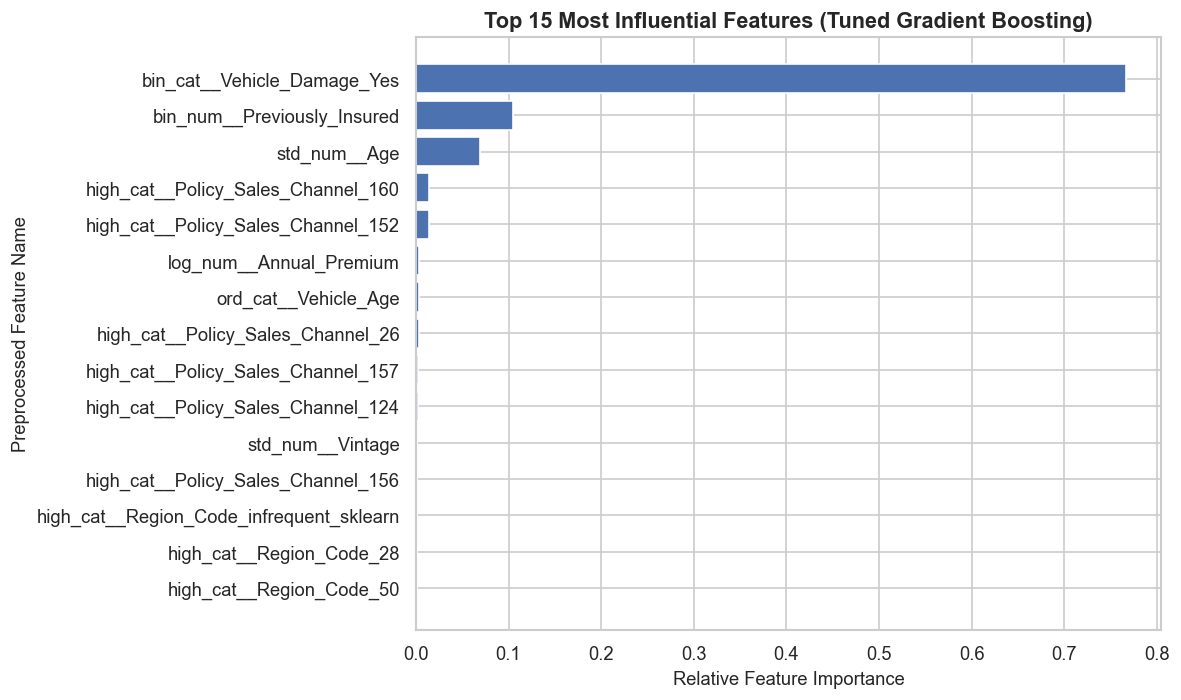

In [2]:
preprocessor = best_model.named_steps['pre']
gb_clf = best_model.named_steps['clf']

feature_names = preprocessor.get_feature_names_out()
importances = gb_clf.feature_importances_

fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

fi_df.to_csv(os.path.join(EVAL_DIR, 'feature_importance.csv'), index=False)
print('--- Top 15 Engineered Features by Gradient Boosting Importance ---')
display(fi_df.head(15).round(5))

top15 = fi_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15['Feature'], top15['Importance'], color='#4C72B0')
ax.set_title('Top 15 Most Influential Features (Tuned Gradient Boosting)', fontsize=13, fontweight='bold')
ax.set_xlabel('Relative Feature Importance', fontsize=11)
ax.set_ylabel('Preprocessed Feature Name', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '18_feature_importance.png'))
plt.show()

## Step 2: Permutation Importance on Raw Input Features (`X_test`)

Permutation importance shuffles one original customer column at a time in `X_test` and measures how much the model's `ROC-AUC` drops. A larger drop means the model relies more heavily on that customer attribute.

--- Permutation Importance (ROC-AUC Drop on Test Set) ---


,Raw_Feature,Mean_AUC_Drop,Std_AUC_Drop
0,Previously_Insured,0.18816,0.00185
1,Vehicle_Damage,0.05619,0.00080
2,Policy_Sales_Channel,0.03264,0.00119
3,Age,0.03104,0.00111
4,Region_Code,0.00491,0.00055
5,Vehicle_Age,0.00381,0.00042
6,Annual_Premium,0.00107,0.00008
7,Gender,0.00033,0.00007
8,Driving_License,0.00014,0.00006
9,Vintage,-0.00005,0.00006


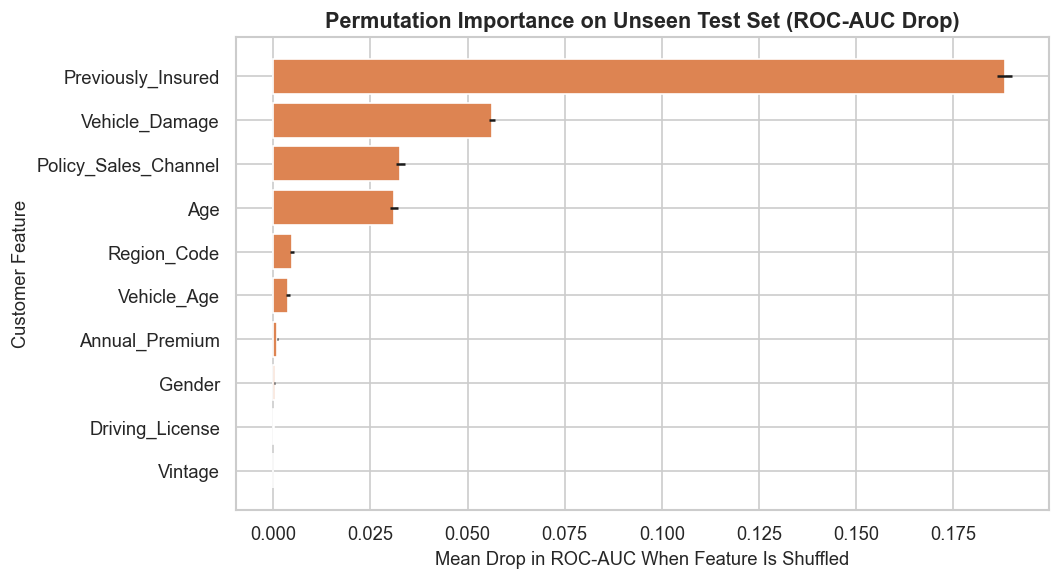

In [3]:
perm_res = permutation_importance(
    best_model, X_test, y_test,
    scoring='roc_auc', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)

perm_df = pd.DataFrame({
    'Raw_Feature': X_test.columns,
    'Mean_AUC_Drop': perm_res.importances_mean,
    'Std_AUC_Drop': perm_res.importances_std
}).sort_values('Mean_AUC_Drop', ascending=False).reset_index(drop=True)

perm_df.to_csv(os.path.join(EVAL_DIR, 'permutation_importance.csv'), index=False)
print('--- Permutation Importance (ROC-AUC Drop on Test Set) ---')
display(perm_df.round(5))

perm_plot = perm_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(perm_plot['Raw_Feature'], perm_plot['Mean_AUC_Drop'], xerr=perm_plot['Std_AUC_Drop'], color='#DD8452')
ax.set_title('Permutation Importance on Unseen Test Set (ROC-AUC Drop)', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean Drop in ROC-AUC When Feature Is Shuffled', fontsize=11)
ax.set_ylabel('Customer Feature', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '19_permutation_importance.png'))
plt.show()

## Step 3: Configurable Threshold Trade-Off Analysis

Because our model outputs probabilities (`0.0` to `1.0`), the business can adjust the decision threshold depending on marketing budget:
- **Lower threshold** (e.g., `0.35–0.50`) → catches more interested customers (**higher Recall**), but contacts more uninterested customers (**lower Precision**).
- **Higher threshold** (e.g., `0.65–0.75`) → contacts fewer, higher-intent customers (**higher Precision**), at the cost of missing some leads (**lower Recall**).

,Threshold,Predicted_Interested,Precision,Recall,F1_Score
0,0.2,38190,0.2421,0.9896,0.3890
1,0.3,35550,0.2571,0.9783,0.4072
2,0.4,33950,0.2657,0.9655,0.4167
3,0.5,30712,0.2826,0.9290,0.4334
4,0.6,26264,0.3059,0.8599,0.4512
5,0.7,20275,0.3326,0.7218,0.4553
6,0.8,4848,0.4088,0.2122,0.2794


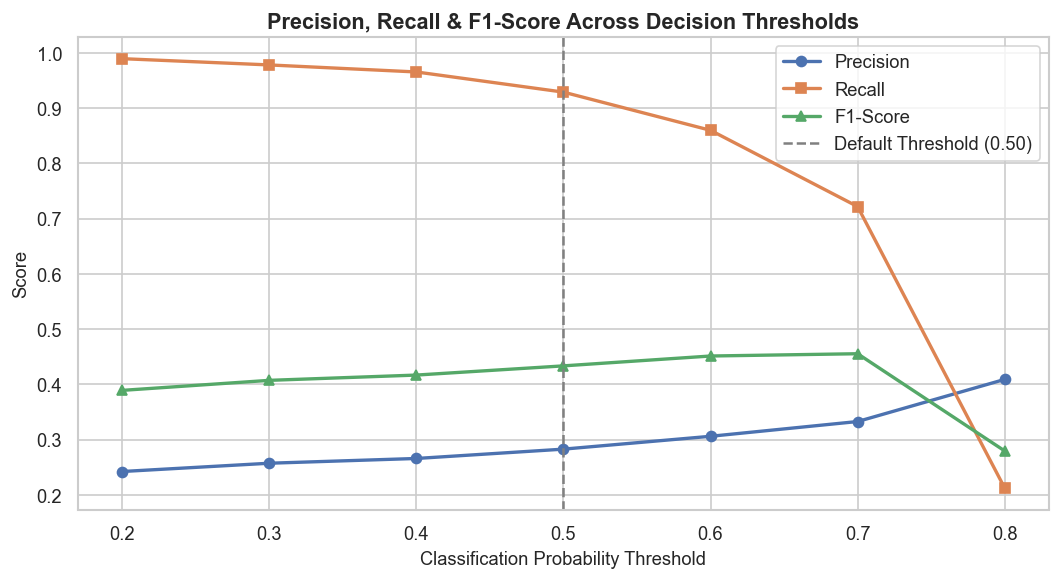

In [4]:
y_prob_test = best_model.predict_proba(X_test)[:, 1]
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
thresh_rows = []
for t in thresholds:
    yp_t = (y_prob_test >= t).astype(int)
    thresh_rows.append({
        'Threshold': t,
        'Predicted_Interested': int(yp_t.sum()),
        'Precision': precision_score(y_test, yp_t, zero_division=0),
        'Recall': recall_score(y_test, yp_t),
        'F1_Score': f1_score(y_test, yp_t)
    })

thresh_df = pd.DataFrame(thresh_rows)
thresh_df.to_csv(os.path.join(EVAL_DIR, 'threshold_tradeoff.csv'), index=False)
display(thresh_df.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresh_df['Threshold'], thresh_df['Precision'], marker='o', linewidth=2, label='Precision')
ax.plot(thresh_df['Threshold'], thresh_df['Recall'], marker='s', linewidth=2, label='Recall')
ax.plot(thresh_df['Threshold'], thresh_df['F1_Score'], marker='^', linewidth=2, label='F1-Score')
ax.axvline(0.50, color='gray', linestyle='--', label='Default Threshold (0.50)')
ax.set_title('Precision, Recall & F1-Score Across Decision Thresholds', fontsize=13, fontweight='bold')
ax.set_xlabel('Classification Probability Threshold', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(GRAPHS_DIR, '20_threshold_tradeoff.png'))
plt.show()

## Step 4: Interpreting Predictions (Correlation / Model Association vs. Causation)

- **Factors Associated with Higher Predicted Interest:**
  - `Previously_Insured = 0` (customer does not currently have vehicle insurance).
  - `Vehicle_Damage = Yes` (customer's vehicle had previous damage).
  - Middle-aged customers (approx. 31–50 years) and older vehicles (`1-2 Year` or `> 2 Years`).
  - Specific high-converting `Policy_Sales_Channel`s (such as channels `26`, `124`, `156`, `157`) and `Region_Code`s.
- **Factors Associated with Lower Predicted Interest:**
  - `Previously_Insured = 1` (already covered elsewhere) and `Vehicle_Damage = No`.
  - Very young customers (`20–30`) with newer vehicles (`< 1 Year`) contacted via low-conversion channels (like `152`).
- **Important Statistical Caveat (Association ≠ Causation):**
  - The model identifies **historical statistical associations**, not causal proof. For example, switching a customer's `Policy_Sales_Channel` does not guarantee they will buy insurance—those channels may simply serve different customer segments or outreach timing.